<h1 style='font-weight:bold'>Steps</h1>

## 1. Preprocess + EDA + Feature Selection
## 2. Extract input and output cols
## 3. Train test split 
## 4. Scale the values 
## 5. Train the model
## 6. Evaluate the model/model selection
## 7. Deploy the model

In [56]:
%pip install mlxtend
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Machine Learning lab is ready!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", mpl.__version__)

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Machine Learning lab is ready!
NumPy version: 2.5.4
Pandas version: 3.1.0
Matplotlib version: 3.11.2


In [5]:
df = pd.read_csv('college_student_placement_dataset.csv')
df

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No
...,...,...,...,...,...,...,...,...,...,...
9995,CLG0021,119,8.41,8.29,4,No,1,8,0,Yes
9996,CLG0098,70,9.25,9.34,7,No,0,7,2,No
9997,CLG0066,89,6.08,6.25,3,Yes,3,9,5,No
9998,CLG0045,107,8.77,8.92,3,No,7,5,1,No


In [6]:
df.head()

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   College_ID              10000 non-null  str    
 1   IQ                      10000 non-null  int64  
 2   Prev_Sem_Result         10000 non-null  float64
 3   CGPA                    10000 non-null  float64
 4   Academic_Performance    10000 non-null  int64  
 5   Internship_Experience   10000 non-null  str    
 6   Extra_Curricular_Score  10000 non-null  int64  
 7   Communication_Skills    10000 non-null  int64  
 8   Projects_Completed      10000 non-null  int64  
 9   Placement               10000 non-null  str    
dtypes: float64(2), int64(5), str(3)
memory usage: 781.4 KB


# **1. Preprocess**

In [8]:
df = df.iloc[:,[i for i in range(len(df.columns)) if i != 4]]

In [9]:
df

,College_ID,IQ,Prev_Sem_Result,CGPA,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,No,8,8,4,No
1,CLG0061,97,5.52,5.37,No,7,8,0,No
2,CLG0036,109,5.36,5.83,No,3,1,1,No
3,CLG0055,122,5.47,5.75,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,No,8,10,2,No
...,...,...,...,...,...,...,...,...,...
9995,CLG0021,119,8.41,8.29,No,1,8,0,Yes
9996,CLG0098,70,9.25,9.34,No,0,7,2,No
9997,CLG0066,89,6.08,6.25,Yes,3,9,5,No
9998,CLG0045,107,8.77,8.92,No,7,5,1,No


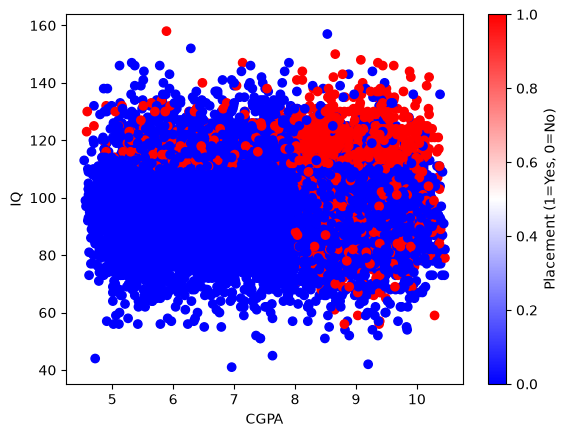

In [13]:
df['Placement_numeric'] = df['Placement'].map({'Yes': 1, 'No': 0})
df['Internship_numeric'] = df['Internship_Experience'].map({'Yes': 1, 'No': 0})
plt.scatter(df['CGPA'], df['IQ'],c=df['Placement_numeric'], cmap='bwr')
plt.xlabel('CGPA')
plt.ylabel('IQ')
plt.colorbar(label='Placement (1=Yes, 0=No)')

In [14]:
df.head()

,College_ID,IQ,Prev_Sem_Result,CGPA,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement,Placement_numeric,Internship_numeric
0,CLG0030,107,6.61,6.28,No,8,8,4,No,0,0
1,CLG0061,97,5.52,5.37,No,7,8,0,No,0,0
2,CLG0036,109,5.36,5.83,No,3,1,1,No,0,0
3,CLG0055,122,5.47,5.75,Yes,1,6,1,No,0,1
4,CLG0004,96,7.91,7.69,No,8,10,2,No,0,0


# **2. Extract input and output cols**

In [15]:
x = df.iloc[:, [1,3]]
y = df.iloc[:, -2]

In [16]:
x.head()
x.shape

(10000, 2)

In [17]:
y.head()
y.shape

(10000,)

# **3. Train_Test_Split** 

In [32]:
# Model Trained on 80:20% Ratio 
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2)

In [33]:
x_train

,IQ,CGPA
769,127,8.72
5911,98,6.44
5565,110,6.43
6112,107,7.61
7341,106,5.95
...,...,...
6549,108,6.97
2161,103,9.03
1294,101,9.60
9991,102,6.86


In [34]:
x_test

,IQ,CGPA
8704,126,5.02
7150,110,6.67
125,132,9.60
6767,104,9.30
4661,95,6.83
...,...,...
3910,78,5.50
3313,84,9.24
6230,104,5.27
4008,92,8.27


In [35]:
y_train

769     1
5911    0
5565    0
6112    0
7341    0
       ..
6549    0
2161    0
1294    0
9991    0
1781    0
Name: Placement_numeric, Length: 8000, dtype: int64

In [36]:
y_test

8704    0
7150    0
125     1
6767    0
4661    0
       ..
3910    0
3313    0
6230    0
4008    1
5881    0
Name: Placement_numeric, Length: 2000, dtype: int64

# **4. Scale the Values**

In [37]:
from sklearn.preprocessing import StandardScaler

In [38]:
scaler = StandardScaler()

In [39]:
x_train = scaler.fit_transform(x_train)

In [40]:
x_train

array([[ 1.82857793,  0.8126404 ],
       [-0.09806794, -0.73995282],
       [ 0.69916484, -0.74676244],
       ...,
       [ 0.10124026,  1.41188691],
       [ 0.16767632, -0.45394881],
       [-0.09806794,  1.39826767]], shape=(8000, 2))

In [41]:
x_test = scaler.transform(x_test)

In [42]:
x_test

array([[ 1.76214186, -1.70691878],
       [ 0.69916484, -0.58333158],
       [ 2.16075825,  1.41188691],
       ...,
       [ 0.30054845, -1.53667829],
       [-0.49668432,  0.50620753],
       [ 1.36352548, -1.33919933]], shape=(2000, 2))

# **5. Train the Model**
# Use the Logistic Regression to Train the Model

In [43]:
from sklearn.linear_model import LogisticRegression

In [44]:
clf = LogisticRegression()

In [45]:
# Model Training on 80%(train) and 20%(test)
clf.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [46]:
y_pred = clf.predict(x_test)

In [47]:
y_test

8704    0
7150    0
125     1
6767    0
4661    0
       ..
3910    0
3313    0
6230    0
4008    1
5881    0
Name: Placement_numeric, Length: 2000, dtype: int64

In [48]:
from sklearn.metrics import accuracy_score

In [49]:
accuracy_score(y_test, y_pred)

0.854

In [60]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

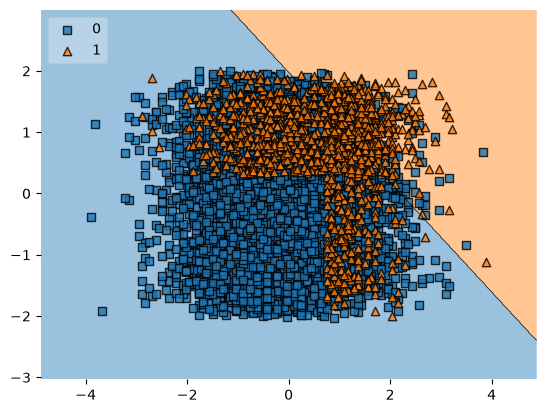

In [61]:
plot_decision_regions(x_train, y_train.values, clf=clf, legend=2)